In [2]:
!pip install scikit-learn==1.9.1

In [3]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import joblib
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix
from keras.layers import Dense, Dropout, Input
from keras.models import Sequential

In [5]:
data = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/deep learning projects/Flight Delay Prediction/us_domestic_flights_delay.csv')
data.head()

,is_delay,Year,Quarter,Month,DayofMonth,DayOfWeek,FlightDate,Reporting_Airline,Origin,OriginState,Dest,DestState,CRSDepTime,Cancelled,Diverted,Distance,DistanceGroup,ArrDelay,ArrDelayMinutes,AirTime
0,1.0,2014,1,1,1,3,2014-01-01,UA,LAX,CA,ORD,IL,900,0.0,0.0,1744.0,7,43.0,43.0,218.0
1,0.0,2014,1,1,1,3,2014-01-01,AA,IAH,TX,DFW,TX,1750,0.0,0.0,224.0,1,2.0,2.0,50.0
2,1.0,2014,1,1,1,3,2014-01-01,AA,LAX,CA,ORD,IL,1240,0.0,0.0,1744.0,7,26.0,26.0,220.0
3,1.0,2014,1,1,1,3,2014-01-01,AA,DFW,TX,LAX,CA,1905,0.0,0.0,1235.0,5,159.0,159.0,169.0
4,0.0,2014,1,1,1,3,2014-01-01,AA,DFW,TX,CLT,NC,1115,0.0,0.0,936.0,4,-13.0,0.0,108.0


In [6]:
avg_delay_by_origin = data.groupby('Origin')['ArrDelay'].mean().reset_index()
bar_plot = px.bar(data_frame=avg_delay_by_origin, x='Origin', y='ArrDelay', title='Average Arrival Delay by Origin Airport')
bar_plot.update_layout(xaxis_title='Origin', yaxis_title='Average Arrival Delay (minutes)')
bar_plot.show()

In [7]:
avg_delay_by_dest = data.groupby('Dest')['ArrDelay'].mean().reset_index()
bar_plot = px.bar(data_frame=avg_delay_by_dest, x='Dest', y='ArrDelay', title='Average Arrival Delay by Destination Airport')
bar_plot.update_layout(xaxis_title='Destination', yaxis_title='Average Arrival Delay (minutes)')
bar_plot.show()

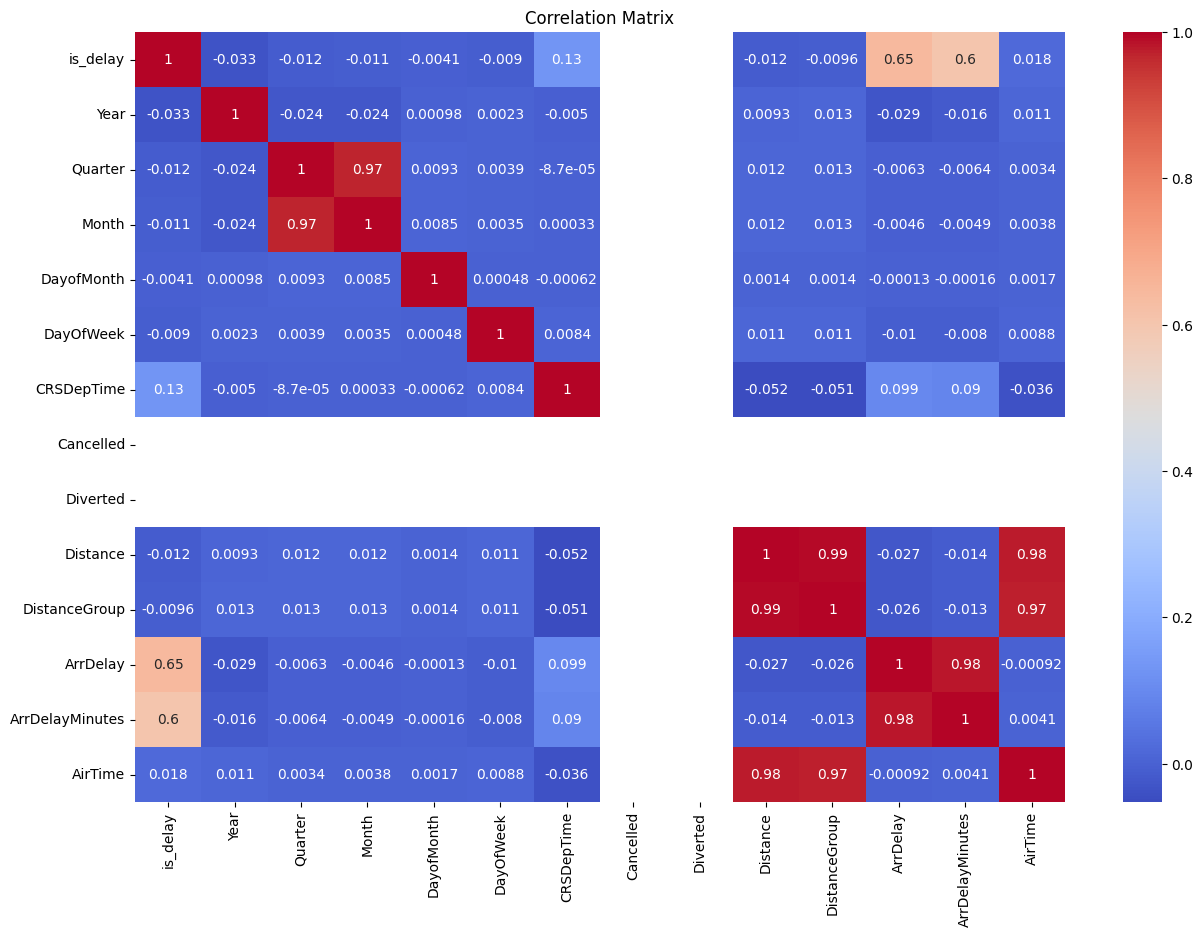

In [8]:
numeric_data = data.select_dtypes(include=['number'])
corr_matrix = numeric_data.corr()
plt.figure(figsize=(15, 10))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm')
plt.title('Correlation Matrix')
plt.show()

In [9]:
data['FlightDate'] = pd.to_datetime(data['FlightDate'])
avg_delay_by_month = data.groupby(data['FlightDate'].dt.month)['is_delay'].mean().reset_index()
fig = px.bar(data_frame=avg_delay_by_month,
             x='FlightDate',
             y='is_delay',
             title='Average Delay by Month')
fig.update_layout(xaxis_title='Month', yaxis_title='Average Delay')
fig.show()


In [10]:
# Split the data into training and testing datasets
X = data[['AirTime', 'Distance']]
y = data[['ArrDelayMinutes', 'is_delay']]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Scale the input features
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [11]:
print(X_train.shape)

(1308472, 2)


In [12]:
# Build the model
BATCH_SIZE = 32
EPOCHS = 5

model = Sequential()
model.add(Input(shape=(X_train.shape[1], )))
model.add(Dense(64, activation='relu'))
model.add(Dropout(0.5))
model.add(Dense(32, activation='relu'))
model.add(Dense(2, activation='linear'))

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │           192 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 2)              │            66 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,338 (9.13 KB)

 Trainable params: 2,338 (9.13 KB)

 Non-trainable params: 0 (0.00 B)

In [13]:
# Compile the model
model.compile(loss='mean_squared_error', optimizer='adam', metrics=['accuracy'])

In [14]:
# Train the model
model.fit(X_train, y_train, epochs=EPOCHS, batch_size=BATCH_SIZE)

Epoch 1/5
40890/40890 ━━━━━━━━━━━━━━━━━━━━ 101s 2ms/step - accuracy: 1.0000 - loss: 777.5632
Epoch 2/5
40890/40890 ━━━━━━━━━━━━━━━━━━━━ 95s 2ms/step - accuracy: 1.0000 - loss: 774.0485
Epoch 3/5
40890/40890 ━━━━━━━━━━━━━━━━━━━━ 96s 2ms/step - accuracy: 1.0000 - loss: 773.8481
Epoch 4/5
40890/40890 ━━━━━━━━━━━━━━━━━━━━ 95s 2ms/step - accuracy: 1.0000 - loss: 773.7496
Epoch 5/5
40890/40890 ━━━━━━━━━━━━━━━━━━━━ 95s 2ms/step - accuracy: 1.0000 - loss: 773.3538


In [15]:
# Evaluate the model
score, accuracy = model.evaluate(X_test, y_test)
print('Test loss:', score)
print('Test accuracy:', accuracy)

10223/10223 ━━━━━━━━━━━━━━━━━━━━ 23s 2ms/step - accuracy: 1.0000 - loss: 728.3907
Test loss: 728.3906860351562
Test accuracy: 1.0


In [16]:
# Save the model
joblib.dump(scaler, '/content/drive/MyDrive/Colab Notebooks/deep learning projects/Flight Delay Prediction/scaler.joblib')
print('Scaler saved successfully!')
model.save('/content/drive/MyDrive/Colab Notebooks/deep learning projects/Flight Delay Prediction/flight_delay_model.keras')
print('Model saved successfully!')

Scaler saved successfully!
Model saved successfully!
